# Micro-loan credit scoring: from a repayment ledger to a scorecard and an early-warning indicator

**Goal.** Estimate, *on the day a micro-loan is requested*, the probability that it will be repaid **7 or more days late**, and turn it into a transparent points-based scorecard that a loan officer can read and explain.

**Data.** Two synthetic core-banking extracts (generated by `data/generate_data.py`, all customers and amounts are fictitious):
- `loans.csv`: one row per loan (customer, branch, booking and maturity dates, amount, status);
- `repayments.csv`: the repayment ledger, one row per transaction (principal, interest, penalty).

Micro-loans here are short (about one month) and repaid in a single instalment at maturity, as in many microfinance products.

**What this notebook shows**
1. Building an exact default target from transaction-level repayments, and why monthly portfolio snapshots miss most late payments.
2. Features known at application time only (no data leakage).
3. WOE binning, information value, logistic regression, points-based scorecard with risk classes A to E.
4. Out-of-time validation: Gini with a bootstrap confidence interval, KS, calibration, population stability.
5. A weekly early-warning indicator that detects a portfolio-wide shock that no individual score can predict.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

sys.path.append(str(Path("..") / "src"))
from scorecard import make_bins, to_bins, woe_table, iv_strength, gini, gini_ci, ks, psi, wilson, scaling

DATA, FIG = Path("../data"), Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
CUTOFF = pd.Timestamp("2025-12-31")          # extraction date: nothing after it is known
DEFAULT_DAYS = 7                             # target: repaid 7 or more days after maturity

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e8ee", "axes.axisbelow": True, "font.size": 10})
NAVY, BLUE, GREEN, ORANGE, RED, GREY = "#123A6B", "#2C6DB3", "#2E8B57", "#E08A1E", "#C0392B", "#9AA0A6"

## 1. The data

In [2]:
loans = pd.read_csv(DATA / "loans.csv", parse_dates=["booking_date", "maturity_date"])
rep = pd.read_csv(DATA / "repayments.csv", parse_dates=["txn_date"])
loans["term_days"] = (loans["maturity_date"] - loans["booking_date"]).dt.days

print(f"{len(loans):,} loans to {loans['customer_id'].nunique():,} customers in {loans['branch'].nunique()} branches, "
      f"booked from {loans['booking_date'].min():%d %b %Y} to {loans['booking_date'].max():%d %b %Y}")
print(f"{len(rep):,} ledger transactions:", rep["tag"].value_counts().to_dict())
print("Term (days), median:", loans["term_days"].median(), "| amount, median:", f"{loans['amount'].median():,.0f}")
loans.head(3)

26,970 loans to 3,600 customers in 12 branches, booked from 02 Jan 2023 to 31 Dec 2025
64,618 ledger transactions: {'PRINCIPAL': 32137, 'INTEREST': 26234, 'PENALTY': 6247}
Term (days), median: 32.0 | amount, median: 300,000


,loan_id,customer_id,branch,booking_date,maturity_date,amount,status,term_days
0,ML000001,C00001,BR07,2024-12-19,2025-01-21,200000.0,LIQUIDATED,33
1,ML000002,C00002,BR02,2023-01-02,2023-02-02,250000.0,LIQUIDATED,31
2,ML000003,C00002,BR02,2023-02-02,2023-03-06,300000.0,LIQUIDATED,32


## 2. An exact target from the repayment ledger

A loan is **settled** on the first day the cumulative principal repaid reaches 99.9% of the amount lent. Its **days late** are the settlement date minus the maturity date (0 if repaid early). A loan still open at the extraction date is *censored*: it is late by **at least** the time elapsed since maturity.

Only **observable** loans are modelled: those whose maturity is at least 45 days before the extraction date, so that their outcome is known.

Observable loans: 25,183 | default rate (7+ days late): 5.5%


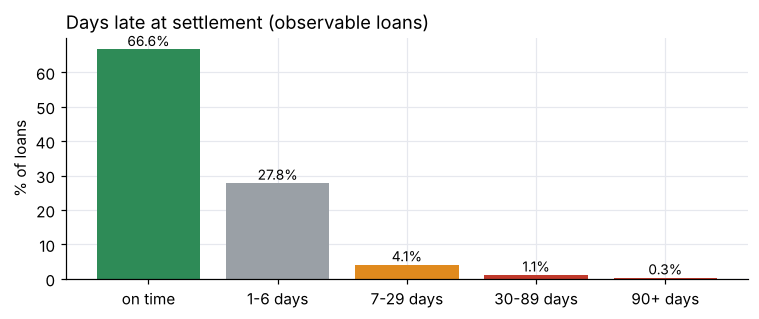

In [3]:
principal = (rep[rep["tag"] == "PRINCIPAL"].groupby(["loan_id", "txn_date"], as_index=False)["amount"].sum()
             .sort_values(["loan_id", "txn_date"]))
principal["cumulative"] = principal.groupby("loan_id")["amount"].cumsum()
principal = principal.merge(loans[["loan_id", "amount"]].rename(columns={"amount": "loan_amount"}), on="loan_id")
settlement = principal[principal["cumulative"] >= 0.999 * principal["loan_amount"]].groupby("loan_id")["txn_date"].min()

loans["settlement_date"] = loans["loan_id"].map(settlement)
loans["days_late"] = (loans["settlement_date"] - loans["maturity_date"]).dt.days.clip(lower=0)
still_open = loans["settlement_date"].isna() & (loans["maturity_date"] < CUTOFF)
loans.loc[still_open, "days_late"] = (CUTOFF - loans.loc[still_open, "maturity_date"]).dt.days
loans["observable"] = loans["maturity_date"] + pd.Timedelta(days=45) <= CUTOFF
loans["default"] = (loans["days_late"] >= DEFAULT_DAYS).astype(int)

obs = loans[loans["observable"]]
buckets = pd.cut(obs["days_late"], [-1, 0, 6, 29, 89, np.inf], labels=["on time", "1-6 days", "7-29 days", "30-89 days", "90+ days"])
dist = buckets.value_counts(normalize=True).sort_index()
print(f"Observable loans: {len(obs):,} | default rate (7+ days late): {obs['default'].mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(dist.index.astype(str), dist.values * 100, color=[GREEN, GREY, ORANGE, RED, RED])
for i, v in enumerate(dist.values):
    ax.text(i, v * 100 + 1, f"{v:.1%}", ha="center", fontsize=9)
ax.set_ylabel("% of loans"); ax.set_title("Days late at settlement (observable loans)", loc="left")
plt.tight_layout(); plt.savefig(FIG / "days_late.png"); plt.show()

### Why monthly portfolio snapshots are not enough

Many institutions track arrears with month-end portfolio extracts. A one-month loan can be booked and settled between two snapshots, so a late payment that is cured before the next month-end is **never seen**. The ledger sees every payment.

In [4]:
month_ends = pd.date_range("2023-01-31", CUTOFF, freq="ME")
seen_late = set()
for s in month_ends:
    late_at_s = obs[(obs["maturity_date"] <= s - pd.Timedelta(days=DEFAULT_DAYS))
                    & (obs["settlement_date"].isna() | (obs["settlement_date"] > s))]
    seen_late |= set(late_at_s["loan_id"])
true_defaults = set(obs.loc[obs["default"] == 1, "loan_id"])
print(f"7+ days late according to the ledger:           {len(true_defaults):,}")
print(f"seen 7+ days late on at least one month-end:    {len(true_defaults & seen_late):,} "
      f"({len(true_defaults & seen_late) / len(true_defaults):.0%} of them)")

7+ days late according to the ledger:           1,396
seen 7+ days late on at least one month-end:    622 (45% of them)


## 3. Features known on the day of the request

Each feature is computed **only from what was known at the booking date** of the loan: previous loans of the same customer booked strictly before, with the delay of each one as it was known then (its final delay if already settled, the days elapsed since its maturity if overdue, unknown otherwise). Using later information (penalties, final status...) would leak the answer into the model.

In [5]:
def history_features(group: pd.DataFrame) -> pd.DataFrame:
    g = group.sort_values(["booking_date", "loan_id"])
    rows = []
    recs = g.to_dict("records")
    for r in recs:
        b = r["booking_date"]
        prev = [j for j in recs if j["booking_date"] < b]
        known = []
        for j in prev:
            if pd.notna(j["settlement_date"]) and j["settlement_date"] <= b:
                known.append(j["days_late"])
            elif j["maturity_date"] < b:
                known.append((b - j["maturity_date"]).days)
        rows.append({
            "loan_id": r["loan_id"],
            "n_prev_loans": len(prev),
            "worst_late_last3": max(known[-3:]) if known else np.nan,
            "share_late7_prev": np.mean([k >= DEFAULT_DAYS for k in known]) if known else np.nan,
            "days_since_prev_maturity": (b - prev[-1]["maturity_date"]).days if prev else np.nan,
            "prev_loan_open": any(pd.isna(j["settlement_date"]) or j["settlement_date"] > b for j in prev),
        })
    return pd.DataFrame(rows)

hist = pd.concat([history_features(g) for _, g in loans.groupby("customer_id")], ignore_index=True)
loans = loans.merge(hist, on="loan_id")
FEATURES = ["worst_late_last3", "share_late7_prev", "n_prev_loans", "days_since_prev_maturity", "prev_loan_open", "term_days", "amount"]
loans[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
worst_late_last3,23370.0,5.10,12.43,0.0,0.0,2.0,5.0,160.0
share_late7_prev,23370.0,0.05,0.14,0.0,0.0,0.0,0.0,1.0
n_prev_loans,26970.0,5.75,5.52,0.0,1.0,4.0,8.0,33.0
days_since_prev_maturity,23370.0,10.76,25.72,-3.0,0.0,2.0,7.0,233.0
term_days,26970.0,32.43,2.52,29.0,31.0,32.0,33.0,40.0
amount,26970.0,361675.94,195565.55,50000.0,200000.0,300000.0,500000.0,700000.0


## 4. Modelling population and out-of-time split

- **History only:** loans booked in 2023 serve only as repayment history; the model is built on loans booked from January 2024, when customers' histories are well filled.
- **External shock:** loans maturing during a temporary market disruption (mid-June to end of July 2025) are left out of training and testing: their late payments reflect a shock common to all customers, not individual risk (section 9 deals with them).
- **Out-of-time split:** the model learns on older loans and is tested on the most recent ones, as it will be used.

In [6]:
SHOCK = (pd.Timestamp("2025-06-16"), pd.Timestamp("2025-07-31"))
in_shock = loans["maturity_date"].between(*SHOCK)
base = loans[loans["observable"] & (loans["booking_date"] >= "2024-01-01") & ~in_shock].copy()
SPLIT = pd.Timestamp("2025-05-01")
train, test = base[base["booking_date"] < SPLIT].copy(), base[base["booking_date"] >= SPLIT].copy()
pd.DataFrame({"period": [f"{d['booking_date'].min():%b %Y} - {d['booking_date'].max():%b %Y}" for d in (train, test)],
              "loans": [len(train), len(test)], "defaults": [train["default"].sum(), test["default"].sum()],
              "default rate": [f"{train['default'].mean():.1%}", f"{test['default'].mean():.1%}"]},
             index=["train", "test (out of time)"])

,period,loans,defaults,default rate
train,Jan 2024 - Apr 2025,11778,586,5.0%
test (out of time),May 2025 - Oct 2025,2780,175,6.3%


## 5. Binning, weight of evidence and information value

Each feature is cut into a few classes (business-meaningful edges where they exist, such as 0 / 1-6 / 7+ days late). The **weight of evidence** (WOE) of a class measures how much more goods than bads it holds; the **information value** (IV) sums this over the classes. All of it is learnt on the training set only.

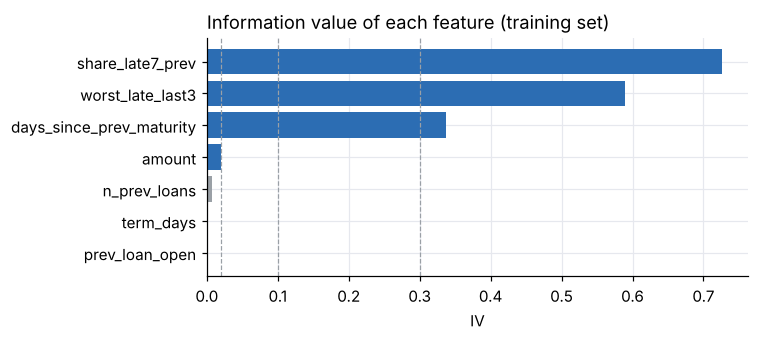

,IV,strength
share_late7_prev,0.726,suspicious
worst_late_last3,0.589,suspicious
days_since_prev_maturity,0.338,strong
amount,0.020,weak
n_prev_loans,0.008,useless
term_days,0.000,useless
prev_loan_open,0.000,useless


In [7]:
EDGES = {"worst_late_last3": [0, 6], "share_late7_prev": [0, 0.3], "n_prev_loans": [0, 3, 7],
         "days_since_prev_maturity": [0, 1, 3, 8], "term_days": [30, 31, 33],
         "amount": [100_000, 250_000, 500_000, 600_000], "prev_loan_open": [0]}
specs, tables = {}, {}
for f in FEATURES:
    x = train[f].astype(float)
    specs[f] = make_bins(x, EDGES.get(f))
    tables[f] = woe_table(to_bins(x, specs[f]), train["default"])
iv = pd.Series({f: t["iv"].sum() for f, t in tables.items()}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(iv.index, iv.values, color=[BLUE if v >= 0.02 else GREY for v in iv.values])
for s in (0.02, 0.1, 0.3):
    ax.axvline(s, color=GREY, lw=0.8, ls="--")
ax.set_title("Information value of each feature (training set)", loc="left"); ax.set_xlabel("IV")
plt.tight_layout(); plt.savefig(FIG / "information_value.png"); plt.show()
pd.DataFrame({"IV": iv.sort_values(ascending=False).round(3), "strength": iv.sort_values(ascending=False).map(iv_strength)})

**A note on the very high IV values.** An IV above 0.5 usually signals *leakage*: a feature that secretly contains the answer. Here, the two repayment-history features are computed only from loans whose outcome was known **before** the booking date (section 3), so there is no leakage: past repayment behaviour is simply the strongest predictor of future behaviour, and the synthetic generator makes it particularly persistent. On real data this check matters just as much, and it is why penalties, final status or settlement dates are never used as features.

In [8]:
tables["worst_late_last3"][["n", "bad", "bad_rate", "woe"]].round(3)

,n,bad,bad_rate,woe
bin,,,,
"(-inf, 0.0]",4056,131,0.032,0.450
"(0.0, 6.0]",5399,183,0.034,0.401
"(6.0, inf]",1110,222,0.200,-1.562
Missing,1213,50,0.041,0.191


## 6. Logistic regression on WOE values

Variables are kept if their IV is at least 0.02, if they are not redundant with a stronger one (|correlation| above 0.6), and if their coefficient is significant (p < 0.05) with the expected sign (negative on WOE).

In [9]:
def woe_values(df, f):
    return to_bins(df[f].astype(float), specs[f]).map(tables[f]["woe"]).fillna(0.0)

for d in (train, test):
    for f in FEATURES:
        d["woe_" + f] = woe_values(d, f)

candidates = [f for f in iv.sort_values(ascending=False).index if iv[f] >= 0.02]
corr = train[["woe_" + f for f in candidates]].corr().abs()
kept = []
for f in candidates:
    if all(corr.loc["woe_" + f, "woe_" + k] <= 0.6 for k in kept):
        kept.append(f)
    else:
        print(f"dropped as redundant: {f}")

while True:
    model = sm.Logit(train["default"], sm.add_constant(train[["woe_" + f for f in kept]])).fit(disp=False)
    coefs, pvals = model.params.drop("const"), model.pvalues.drop("const")
    bad = [c for c in coefs.index if pvals[c] > 0.05 or coefs[c] > 0]
    if not bad:
        break
    worst = max(bad, key=lambda c: pvals[c])
    print(f"dropped: {worst[4:]} (p = {pvals[worst]:.3f}, coef = {coefs[worst]:+.3f})")
    kept.remove(worst[4:])
print("Final variables:", kept)
model.summary2().tables[1].round(3)

dropped as redundant: worst_late_last3
Final variables: ['share_late7_prev', 'days_since_prev_maturity', 'amount']


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-2.942,0.046,-63.752,0.000,-3.032,-2.851
woe_share_late7_prev,-0.859,0.046,-18.616,0.000,-0.950,-0.769
woe_days_since_prev_maturity,-0.576,0.076,-7.547,0.000,-0.726,-0.426
woe_amount,-0.749,0.305,-2.457,0.014,-1.347,-0.151


## 7. Out-of-time validation

Gini train 0.433 | Gini test 0.457 (95% CI 0.371 to 0.542) | KS test 0.356
PSI train -> test: 0.027 (below 0.10 = stable)


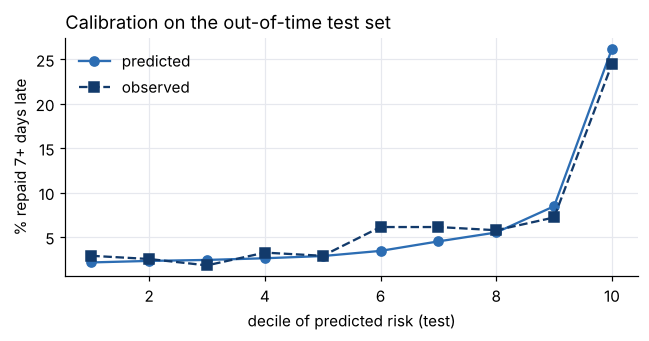

In [10]:
X_train, X_test = sm.add_constant(train[["woe_" + f for f in kept]]), sm.add_constant(test[["woe_" + f for f in kept]])
train["pd"], test["pd"] = model.predict(X_train), model.predict(X_test)
lo, hi = gini_ci(test["default"], test["pd"])
print(f"Gini train {gini(train['default'], train['pd']):.3f} | Gini test {gini(test['default'], test['pd']):.3f} "
      f"(95% CI {lo:.3f} to {hi:.3f}) | KS test {ks(test['default'], test['pd']):.3f}")
print(f"PSI train -> test: {psi(train['pd'], test['pd']):.3f} (below 0.10 = stable)")

test["decile"] = pd.qcut(test["pd"].rank(method="first"), 10, labels=range(1, 11))
cal = test.groupby("decile", observed=True).agg(predicted=("pd", "mean"), observed=("default", "mean"))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(cal.index.astype(int), cal["predicted"] * 100, "o-", color=BLUE, label="predicted")
ax.plot(cal.index.astype(int), cal["observed"] * 100, "s--", color=NAVY, label="observed")
ax.set_xlabel("decile of predicted risk (test)"); ax.set_ylabel("% repaid 7+ days late")
ax.set_title("Calibration on the out-of-time test set", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "calibration.png"); plt.show()

## 8. Points-based scorecard and risk classes

Points are scaled so that **600 points = 10 goods for 1 bad** and **+20 points double the odds**. Each class of each variable gets a whole number of points, so a loan officer can add them up and explain the score. Risk classes A to E are the score quintiles of the training set.

In [11]:
factor, offset = scaling(600, 10, 20)
base_points = int(round(offset - factor * model.params["const"]))
rows = []
for f in kept:
    b = model.params["woe_" + f]
    for cls, r in tables[f].iterrows():
        rows.append({"variable": f, "class": cls, "bad rate (train)": r["bad_rate"], "points": int(round(-factor * b * r["woe"]))})
card = pd.DataFrame(rows)

def score(d):
    s = pd.Series(base_points, index=d.index, dtype=float)
    for f in kept:
        pts = card[card["variable"] == f].set_index("class")["points"]
        s += to_bins(d[f].astype(float), specs[f]).map(pts).fillna(0)
    return s

train["score"], test["score"] = score(train), score(test)
cuts = np.quantile(train["score"], [0.2, 0.4, 0.6, 0.8])
letters = ["E", "D", "C", "B", "A"]
for d in (train, test):
    d["risk_class"] = pd.cut(d["score"], [-np.inf, *cuts, np.inf], labels=letters, duplicates="drop")
print(f"Base points: {base_points}")
card.style.format({"bad rate (train)": "{:.1%}"}).hide(axis="index")

Base points: 618


variable,class,bad rate (train),points
share_late7_prev,"(-inf, 0.0]",2.9%,14
share_late7_prev,"(0.0, 0.3]",8.2%,-13
share_late7_prev,"(0.3, inf]",30.6%,-53
share_late7_prev,Missing,4.1%,5
days_since_prev_maturity,"(-inf, 0.0]",3.3%,7
days_since_prev_maturity,"(0.0, 1.0]",2.3%,13
days_since_prev_maturity,"(1.0, 3.0]",2.9%,9
days_since_prev_maturity,"(3.0, 8.0]",4.0%,4
days_since_prev_maturity,"(8.0, inf]",11.3%,-15
days_since_prev_maturity,Missing,4.1%,3


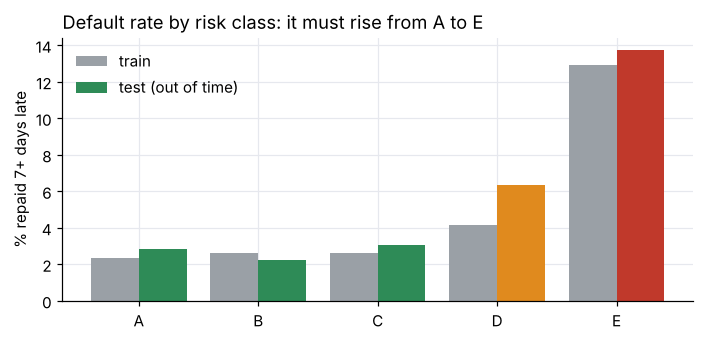

Flagging class E on the test set: 26% of loans, 57% of late payments; default rate 13.7% vs 3.7% for the others.


train        test       
            size   mean size   mean
risk_class                         
A           1524  0.024  314  0.029
B           2712  0.026  585  0.022
C           2810  0.026  617  0.031
D           2356  0.042  535  0.064
E           2376  0.129  729  0.137

In [12]:
by_class = pd.concat({n: d.groupby("risk_class", observed=False)["default"].agg(["size", "mean"]) for n, d in [("train", train), ("test", test)]}, axis=1)
by_class = by_class.loc[["A", "B", "C", "D", "E"]]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(5)
ax.bar(x - 0.2, by_class[("train", "mean")] * 100, 0.4, color=GREY, label="train")
ax.bar(x + 0.2, by_class[("test", "mean")] * 100, 0.4, color=[GREEN, GREEN, GREEN, ORANGE, RED], label="test (out of time)")
ax.set_xticks(x, by_class.index); ax.set_ylabel("% repaid 7+ days late")
ax.set_title("Default rate by risk class: it must rise from A to E", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "default_rate_by_class.png"); plt.show()

flag = test["risk_class"] == "E"
print(f"Flagging class E on the test set: {flag.mean():.0%} of loans, {test.loc[flag, 'default'].sum() / test['default'].sum():.0%} "
      f"of late payments; default rate {test.loc[flag, 'default'].mean():.1%} vs {test.loc[~flag, 'default'].mean():.1%} for the others.")
by_class.round(3)

## 9. Early-warning indicator: a shock no individual score can predict

Every Monday, the indicator computes the share of loans that matured during the previous 30 days (and whose 7-day outcome is already known) that were repaid 7+ days late. It raises an **alert** when the lower bound of its 95% confidence interval exceeds the normal level, and a **strong alert** when the rate also reaches twice the normal level. It uses only information available on that Monday.

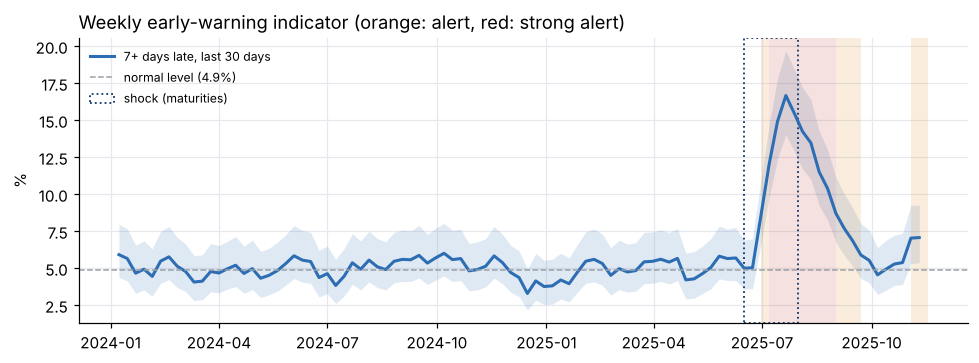

Before the shock: 0 alert week(s) out of 76
First alert after the shock: 30 Jun 2025, 14 days after the first affected maturity (the earliest possible is 8 days, since a 7-day delay takes 7 days to be known)


In [13]:
ref = obs[(obs["maturity_date"] >= "2024-01-01") & (obs["maturity_date"] < "2025-01-01")]["default"].mean()   # normal level = 2024
rows = []
for d in pd.date_range("2024-01-08", CUTOFF - pd.Timedelta(days=45), freq="W-MON"):
    w = obs[(obs["maturity_date"] >= d - pd.Timedelta(days=37)) & (obs["maturity_date"] < d - pd.Timedelta(days=7))]
    k, n = int(w["default"].sum()), len(w)
    lo, hi = wilson(k, n)
    level = "strong alert" if lo > ref and k / n >= 2 * ref else "alert" if lo > ref else "normal"
    rows.append({"monday": d, "loans": n, "rate": k / n, "low": lo, "high": hi, "level": level})
thermo = pd.DataFrame(rows).set_index("monday")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(thermo.index, thermo["low"] * 100, thermo["high"] * 100, color=BLUE, alpha=0.15, lw=0)
ax.plot(thermo.index, thermo["rate"] * 100, color=BLUE, lw=2, label="7+ days late, last 30 days")
ax.axhline(ref * 100, color=GREY, ls="--", lw=1, label=f"normal level ({ref:.1%})")
for d, lvl in thermo["level"].items():
    if lvl != "normal":
        ax.axvspan(d, d + pd.Timedelta(days=7), color=RED if lvl == "strong alert" else ORANGE, alpha=0.15, lw=0)
ax.axvspan(*SHOCK, color="none", ec=NAVY, ls=":", lw=1.2, label="shock (maturities)")
ax.set_ylabel("%"); ax.set_title("Weekly early-warning indicator (orange: alert, red: strong alert)", loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "early_warning.png"); plt.show()

# a Monday can only "see" the shock once its window contains shocked maturities whose 7-day outcome is known
can_see = thermo.index > SHOCK[0] + pd.Timedelta(days=DEFAULT_DAYS)
first = thermo.index[can_see & (thermo["level"] != "normal")]
false_alarms = int((thermo.loc[~can_see & (thermo.index < SHOCK[0] + pd.Timedelta(days=DEFAULT_DAYS)), "level"] != "normal").sum())
weeks = len(thermo.loc[: SHOCK[0]])
print(f"Before the shock: {false_alarms} alert week(s) out of {weeks}")
print(f"First alert after the shock: {first[0]:%d %b %Y}, {(first[0] - SHOCK[0]).days} days after the first affected maturity "
      f"(the earliest possible is {DEFAULT_DAYS + 1} days, since a 7-day delay takes 7 days to be known)")

## 10. Conclusions

- The repayment ledger gives an **exact** target; month-end snapshots miss most short-lived late payments.
- A handful of variables known at application time, above all the **customer's recent repayment behaviour**, separate risky loans from safe ones, and the score keeps its ranking power and calibration on more recent loans.
- The scorecard turns into simple points and five risk classes that a loan officer can read and explain. Classes A to C behave alike, so in practice three levels are enough (A–C standard, D monitor, E act); class E is the natural target for **reminders before maturity**.
- Portfolio-wide shocks are not predictable from individual profiles: they call for a **network-level early-warning indicator**, which complements the individual score.

*Limits:* synthetic data; customers without history are hard to score (the next step would be savings behaviour); the scorecard should be re-estimated periodically and its stability monitored (PSI, default rate by class).